In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [24]:
df = pd.read_csv('Base_de_Datos_dynamic_pricing.csv')

### verificación

In [25]:
df.head()

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Number_of_Riders         1000 non-null   int64  
 1   Number_of_Drivers        1000 non-null   int64  
 2   Location_Category        1000 non-null   str    
 3   Customer_Loyalty_Status  1000 non-null   str    
 4   Number_of_Past_Rides     1000 non-null   int64  
 5   Average_Ratings          1000 non-null   float64
 6   Time_of_Booking          1000 non-null   str    
 7   Vehicle_Type             1000 non-null   str    
 8   Expected_Ride_Duration   1000 non-null   int64  
 9   Historical_Cost_of_Ride  1000 non-null   float64
dtypes: float64(2), int64(4), str(4)
memory usage: 78.3 KB


In [27]:
df['Expected_Ride_Duration'].describe()

count    1000.00000
mean       99.58800
std        49.16545
min        10.00000
25%        59.75000
50%       102.00000
75%       143.00000
max       180.00000
Name: Expected_Ride_Duration, dtype: float64

In [28]:
df['Expected_Ride_Duration'].isna().sum()

np.int64(0)

### Desarrollo

In [29]:
n = 30
r = 1000

In [30]:
poblacion = df['Expected_Ride_Duration'].dropna().values

In [31]:
medias = []

In [32]:
for _ in range(r):
    muestra = np.random.choice(poblacion, size=n, replace=True)
    medias.append(muestra.mean())

In [33]:
medias = np.array(medias)

In [34]:
print("Cantidad de medias: ", len(medias))
print("Meida de las medias: ", medias.mean())
print("Media de la población: ", poblacion.mean())


Cantidad de medias:  1000
Meida de las medias:  99.3952
Media de la población:  99.588


Graficar la distribución de las medias muestrales.

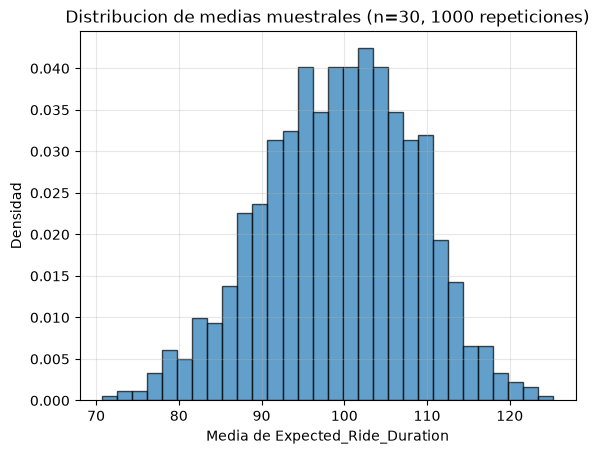

In [35]:
plt.Figure(figsize=(8, 5))
plt.hist(medias, bins=30, density=True, alpha=0.7, edgecolor="black")
plt.title(f"Distribucion de medias muestrales (n={n}, {r} repeticiones)")
plt.xlabel("Media de Expected_Ride_Duration")
plt.ylabel("Densidad")
plt.grid(alpha=0.3)
plt.show()

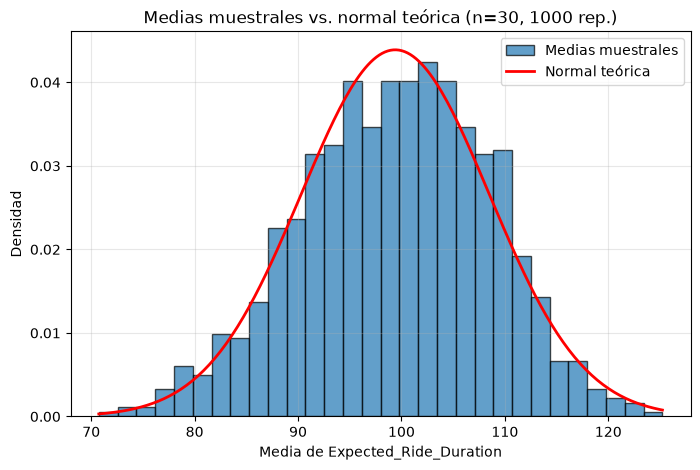

Media de las medias:       99.3952
Media poblacional:         99.588
SD observada de medias:    9.09005717433978
SD predicha por TCL:       8.976342049145071
Shapiro-Wilk: stat=0.9966, p=0.0304


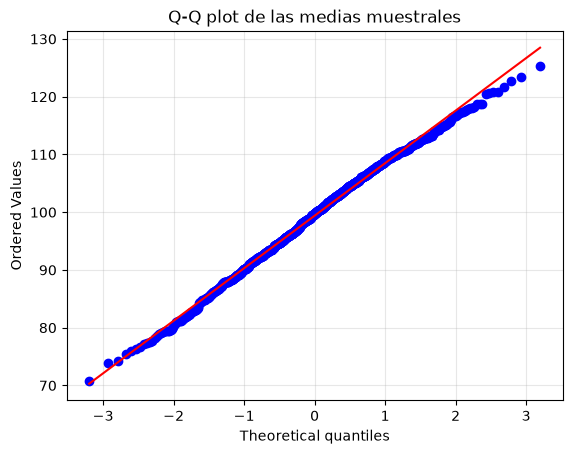

In [ ]:

mu = medias.mean()
sigma = medias.std(ddof=1)

plt.figure(figsize=(8, 5))
plt.hist(medias, bins=30, density=True, alpha=0.7, edgecolor="black", label="Medias muestrales")
x = np.linspace(medias.min(), medias.max(), 200)
plt.plot(x, stats.norm.pdf(x, mu, sigma), color="red", linewidth=2, label="Normal teórica")
plt.title(f"Medias muestrales vs. normal teórica (n={n}, {r} rep.)")
plt.xlabel("Media de Expected_Ride_Duration")
plt.ylabel("Densidad")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

poblacion = df["Expected_Ride_Duration"].dropna()
sigma_pob = poblacion.std(ddof=1)
sigma_tcl = sigma_pob / np.sqrt(n)

print("Media de las medias:      ", medias.mean())
print("Media poblacional:        ", poblacion.mean())
print("SD observada de medias:   ", medias.std(ddof=1))
print("SD predicha por TCL:      ", sigma_tcl)

# --- C) Test de normalidad + Q-Q plot ---
stat, p = stats.shapiro(medias)
print(f"Shapiro-Wilk: stat={stat:.4f}, p={p:.4f}")

stats.probplot(medias, dist="norm", plot=plt)
plt.title("Q-Q plot de las medias muestrales")
plt.grid(alpha=0.3)
plt.show()

## Interpretación de los resultados

En este ejercicio se aplicó el Teorema Central del Límite a la variable `Expected_Ride_Duration`, utilizando una población de 1000 duraciones esperadas de viaje. La media poblacional observada fue de **99.588 minutos** y la desviación estándar fue aproximadamente de **49.165 minutos**. Estos valores muestran que, aunque la duración promedio se encuentra cercana a los 100 minutos, existe una variabilidad importante entre los viajes individuales.

Para estudiar el comportamiento de las medias muestrales se generaron **1000 muestras aleatorias**, cada una con un tamaño de **30 observaciones** y con reemplazo. De cada muestra se calculó la media, obteniendo así una distribución de 1000 medias muestrales. Esta simulación permite analizar no solo los datos individuales, sino también el comportamiento del estadístico media cuando se repite el proceso de muestreo.

La media de las medias muestrales fue de **99.3952 minutos**, mientras que la media de la población fue de **99.588 minutos**. La diferencia entre ambos valores es de aproximadamente **0.193 minutos**, es decir, cerca de 12 segundos. Esta diferencia es pequeña y se debe a la variabilidad natural del muestreo. El resultado evidencia que la media muestral es un estimador centrado y tiende a aproximarse a la media poblacional cuando se realizan muchas repeticiones.

La desviación estándar observada de las medias muestrales fue de **9.0901 minutos**, mientras que la desviación estándar predicha por el TCL fue de **8.9763 minutos**. Ambos valores son muy cercanos. Teóricamente, el error estándar de la media se calcula como `sigma / sqrt(n)`, por lo que al aumentar el tamaño de la muestra la distribución de las medias se concentra alrededor de la media poblacional. En este caso, el tamaño muestral de 30 reduce considerablemente la dispersión de las medias con respecto a la dispersión de los datos individuales.

El histograma de las medias muestrales presenta una forma aproximadamente acampanada y centrada alrededor de 99.5 minutos. Además, la curva normal teórica se ajusta de manera razonable a la distribución simulada. El gráfico Q-Q también permite observar una alineación general de los puntos con la recta teórica, lo que respalda visualmente la aproximación normal de la distribución muestral.

El resultado de la prueba de Shapiro-Wilk fue `p = 0.0304`. Como este valor es menor que 0.05, se rechaza formalmente la hipótesis de normalidad exacta al nivel de significancia del 5 %. Sin embargo, este resultado debe interpretarse con cautela: la prueba se aplicó a 1000 medias muestrales y, con tamaños de datos grandes, puede detectar desviaciones pequeñas respecto a una normalidad perfecta. Por esta razón, la conclusión no debe basarse únicamente en el p-valor, sino también en el histograma, el gráfico Q-Q y la cercanía entre la desviación estándar observada y la predicha por el TCL.

En conjunto, la simulación proporciona evidencia empírica favorable al Teorema Central del Límite. La distribución de las medias muestrales es mucho más estable que la distribución de las duraciones individuales, se concentra alrededor de la media poblacional y presenta una forma aproximadamente normal. La normalidad no tiene que ser perfecta para que los métodos inferenciales sean útiles; lo importante es que la distribución muestral tenga un comportamiento suficientemente cercano al normal bajo las condiciones del análisis.

Esta propiedad justifica el uso de intervalos de confianza, pruebas de hipótesis y otros modelos inferenciales para estimar parámetros poblacionales a partir de muestras. En términos prácticos, aunque no se conozca la media real de todos los viajes de la población, es posible utilizar una muestra de tamaño adecuado para obtener una estimación confiable de dicha media y cuantificar la incertidumbre asociada. Por tanto, el TCL constituye el fundamento teórico que permite pasar del análisis de una muestra a conclusiones razonables sobre la población de viajes.